## 1. Business and records

The three shops have six months of sales to help the team understand what customers buy. We begin by checking what the file contains. Each row records a product sale and its quantity, rather than a customer or a complete order. Revenue is quantity multiplied by unit price, reported in the original currency units (CU).

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / 'config/experiment.json').exists())
config = json.loads((ROOT / 'config/experiment.json').read_text())
source = (ROOT / config['source']).resolve()
assert hashlib.sha256(source.read_bytes()).hexdigest() == config['source_sha256']
raw = pd.read_excel(source)

plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#0A66C2', '#2A9D8F', '#C77800']
pd.set_option('display.max_colwidth', 65)

def note(text):
    display(HTML('<p>' + escape(text) + '</p>'))

profile = pd.Series({'Recorded rows': len(raw), 'Columns': raw.shape[1],
                     'Stores': raw.store_id.nunique(), 'Products': raw.product_id.nunique(),
                     'First date': str(raw.transaction_date.min().date()),
                     'Last date': str(raw.transaction_date.max().date())}, name='Value')
display(profile.to_frame())
display(raw[['transaction_id', 'transaction_date', 'store_location',
             'product_id', 'transaction_qty', 'unit_price']].head(5))

,Value
Recorded rows,149116
Columns,11
Stores,3
Products,80
First date,2023-01-01
Last date,2023-06-30


,transaction_id,transaction_date,store_location,product_id,transaction_qty,unit_price
0,1,2023-01-01,Lower Manhattan,32,2,3.0
1,2,2023-01-01,Lower Manhattan,57,2,3.1
2,3,2023-01-01,Lower Manhattan,59,2,4.5
3,4,2023-01-01,Lower Manhattan,22,1,2.0
4,5,2023-01-01,Lower Manhattan,57,2,3.1


## 2. Consistent labels

Before comparing products or dates, we make their labels and formats consistent. A trailing space can split one product into two labels, while correctly formatted dates and times let us group sales by day and hour. We make these changes on a copy of the original records.

In [2]:
sales = raw.copy()
text_columns = ['store_location', 'product_category', 'product_type', 'product_detail']
space_counts = {}
for column in text_columns:
    cleaned = sales[column].str.strip()
    space_counts[column] = int(sales[column].ne(cleaned).sum())
    sales[column] = cleaned
sales['date'] = pd.to_datetime(sales['transaction_date'], errors='coerce').dt.normalize()
time_values = pd.to_datetime(sales['transaction_time'].astype(str),
                             format='%H:%M:%S', errors='coerce')
sales['hour'] = time_values.dt.hour
for column in ['transaction_qty', 'unit_price']:
    sales[column] = pd.to_numeric(sales[column], errors='coerce')
store_labels = {store_id: f'Store {letter}' for store_id, letter in
                zip(sorted(sales.store_id.unique()), ['A', 'B', 'C'])}
sales['store_label'] = sales.store_id.map(store_labels)
text_changes = pd.Series(space_counts, name='Rows cleaned')
display(text_changes[text_changes.gt(0)].to_frame())
note('We removed a trailing space from 1,952 Scottish Cream Scone records. No other text labels needed trimming; quantities and prices are unchanged. After inspecting the source locations, the Singapore scenario relabels the three source store IDs as Store A, Store B and Store C.')

,Rows cleaned
product_detail,1952


## 3. Missing and duplicate rows

Missing information or duplicate records could distort sales totals. We check for missing fields, repeated rows and IDs, and quantities or prices that cannot be read as positive numbers.

In [3]:
checks = pd.Series({
    'Missing source values': int(raw.isna().sum().sum()),
    'Unparsed dates': int(sales.date.isna().sum()),
    'Unparsed times': int(sales.hour.isna().sum()),
    'Duplicate transaction IDs': int(sales.transaction_id.duplicated().sum()),
    'Duplicate complete rows': int(raw.duplicated().sum()),
    'Unparsed quantities': int(sales.transaction_qty.isna().sum()),
    'Unparsed prices': int(sales.unit_price.isna().sum()),
    'Nonpositive quantities': int(sales.transaction_qty.le(0).sum()),
    'Nonpositive prices': int(sales.unit_price.le(0).sum())}, name='Rows / values flagged')
quality = checks.to_frame()
quality['Action'] = 'No correction needed'
display(quality)
assert checks.eq(0).all(), 'Review flagged records before continuing.'
id_gaps = int(raw.transaction_id.max() - raw.transaction_id.min() + 1
              - raw.transaction_id.nunique())
note(f'All {len(sales):,} rows pass these checks. The {id_gaps:,} gaps in the ID sequence do not establish that sales are missing, so no rows are added or IDs changed.')

,Rows / values flagged,Action
Missing source values,0,No correction needed
Unparsed dates,0,No correction needed
Unparsed times,0,No correction needed
Duplicate transaction IDs,0,No correction needed
Duplicate complete rows,0,No correction needed
Unparsed quantities,0,No correction needed
Unparsed prices,0,No correction needed
Nonpositive quantities,0,No correction needed
Nonpositive prices,0,No correction needed


## 4. Unusual values

An unusual value is not necessarily a mistake. We review products with more than one recorded price, then check whether larger sale quantities need attention.

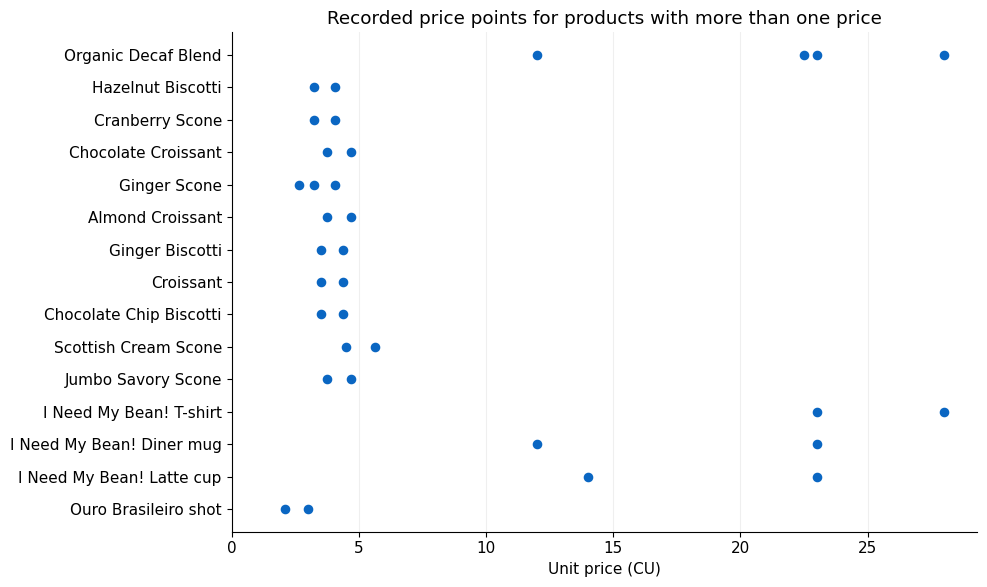

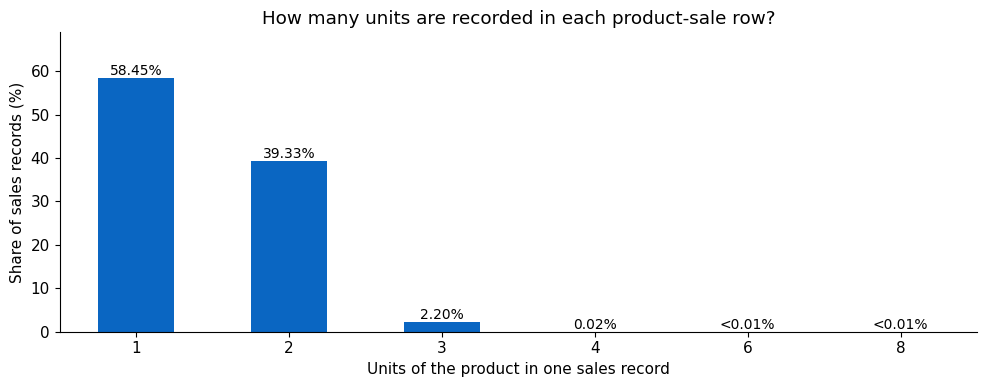

In [4]:
price_check = sales.groupby('product_id').agg(
    Product=('product_detail', 'first'), Prices=('unit_price', 'nunique'))
variable_prices = price_check.loc[price_check.Prices.gt(1)].sort_index()
price_counts = sales.groupby(['product_id', 'unit_price']).size().rename('Rows').reset_index()
price_counts = price_counts.loc[price_counts.product_id.isin(variable_prices.index)]
fig, ax = plt.subplots(figsize=(10, 6))
for position, product_id in enumerate(variable_prices.index):
    points = price_counts.loc[price_counts.product_id.eq(product_id)]
    ax.scatter(points.unit_price, [position] * len(points), color=COLORS[0], s=35)
ax.set_yticks(range(len(variable_prices)), variable_prices.Product)
ax.invert_yaxis()
ax.set_title('Recorded price points for products with more than one price')
ax.set_xlabel('Unit price (CU)')
ax.set_xlim(left=0)
ax.grid(axis='x', alpha=0.2)
plt.tight_layout(); plt.show()
note(f'Each dot represents a recorded price. {len(variable_prices)} products have more than one price, but the file does not explain the differences. We retain the recorded prices.')

price_register = price_counts.merge(variable_prices[['Product']], on='product_id')
price_register = price_register[['product_id', 'Product', 'unit_price', 'Rows']]
price_register.to_csv(ROOT / 'results/eda/price_review.csv', index=False)

quantity_share = sales.transaction_qty.value_counts(normalize=True).sort_index().mul(100)
ax = quantity_share.plot.bar(color=COLORS[0], rot=0)
quantity_labels = [f'{value:.2f}%' if value >= 0.01 else '<0.01%' for value in quantity_share]
ax.bar_label(ax.containers[0], labels=quantity_labels, fontsize=10)
ax.set_ylim(0, quantity_share.max() * 1.18)
ax.set_title('How many units are recorded in each product-sale row?')
ax.set_xlabel('Units of the product in one sales record'); ax.set_ylabel('Share of sales records (%)')
plt.tight_layout(); plt.show()
note('A Latte record with a quantity of 2 means that this row records two cups of Latte. The chart counts product-sale rows, not customers or complete orders.')
note(f'{quantity_share.get(1, 0):.2f}% of records contain one unit and {quantity_share.get(2, 0):.2f}% contain two. Larger quantities are uncommon, but may represent valid purchases, so we retain them rather than treating them as errors.')

## 5. Daily sales records

We now combine purchases into daily totals for each shop. First, we check that every shop has records throughout the calendar, so a missing day is not mistaken for a day with no sales.

In [5]:
sales['month'] = sales.date.dt.to_period('M').astype(str)
sales['weekday'] = sales.date.dt.dayofweek
sales['revenue'] = sales.transaction_qty * sales.unit_price
calendar = pd.date_range(sales.date.min(), sales.date.max(), freq='D')
store_names = sales.groupby('store_id').store_label.first()
daily = sales.groupby(['store_id', 'date']).agg(
    units=('transaction_qty', 'sum'), revenue=('revenue', 'sum'),
    records=('transaction_id', 'size')).reset_index()
coverage = daily.groupby('store_id').agg(
    First=('date', 'min'), Last=('date', 'max'), Days=('date', 'nunique'))
coverage['Days without records'] = len(calendar) - coverage.Days
coverage.index = coverage.index.map(store_names)
display(coverage)
assert coverage['Days without records'].eq(0).all()
assert np.isclose(daily.revenue.sum(), sales.revenue.sum())
assert daily.units.sum() == sales.transaction_qty.sum()
note('All three shops have sales records on every one of the 181 days. The daily totals match the original quantities and revenue, so no shop-day totals need to be filled in.')

,First,Last,Days,Days without records
store_id,,,,
Store A,2023-01-01,2023-06-30,181,0
Store B,2023-01-01,2023-06-30,181,0
Store C,2023-01-01,2023-06-30,181,0


## 6. Sales by shop

The hub serves three shops. Comparing their units and revenue shows whether one shop accounts for most of the business or whether activity is more evenly spread.

,Records,Units,Revenue_CU,Revenue share (%)
store_label,,,,
Store A,50599,70991,232243.91,33.23
Store B,47782,71742,230057.25,32.92
Store C,50735,71737,236511.17,33.84


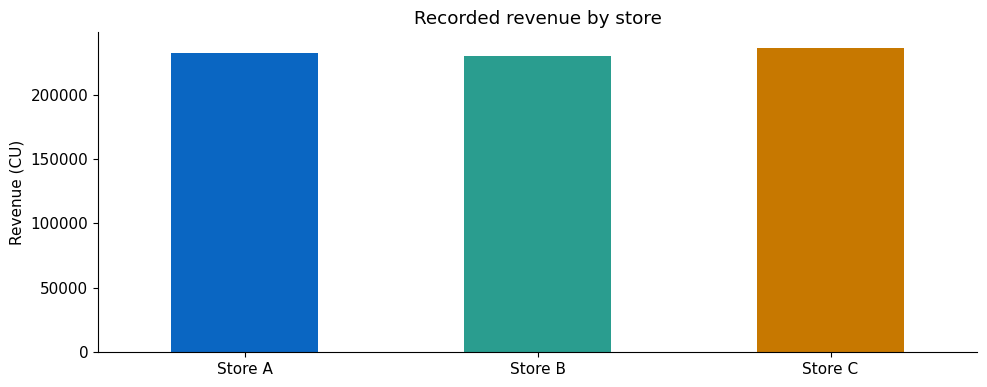

In [6]:
store_summary = sales.groupby('store_label').agg(
    Records=('transaction_id', 'size'), Units=('transaction_qty', 'sum'),
    Revenue_CU=('revenue', 'sum'))
store_summary['Revenue share (%)'] = 100 * store_summary.Revenue_CU / store_summary.Revenue_CU.sum()
display(store_summary.round(2))
store_summary.Revenue_CU.plot.bar(color=COLORS, rot=0)
plt.title('Recorded revenue by store'); plt.ylabel('Revenue (CU)'); plt.xlabel('')
plt.tight_layout(); plt.show()
note(f'Revenue shares range from {store_summary["Revenue share (%)"].min():.1f}% to {store_summary["Revenue share (%)"].max():.1f}%. The three shops contribute similar shares of recorded revenue.')

## 7. Business growth

The six-month totals hide how the young business changes over time. We follow each shop month by month, using average sales per day so longer months do not automatically appear stronger.

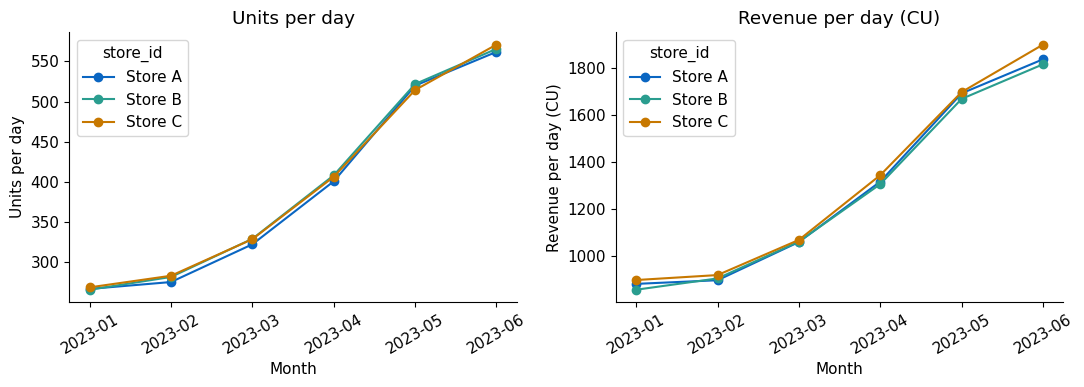

In [7]:
daily['month'] = daily.date.dt.to_period('M').astype(str)
monthly = daily.groupby(['month', 'store_id'])[['units', 'revenue']].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, label in zip(axes, ['units', 'revenue'], ['Units per day', 'Revenue per day (CU)']):
    values = monthly[metric].unstack().rename(columns=store_names)
    values.plot(ax=ax, marker='o', color=COLORS)
    ax.set_title(label); ax.set_xlabel('Month'); ax.set_ylabel(label)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
network_daily = daily.groupby('date')[['units', 'revenue', 'records']].sum()
monthly_average = network_daily.groupby(network_daily.index.to_period('M')).mean()
change = 100 * (monthly_average.revenue.iloc[-1] / monthly_average.revenue.iloc[0] - 1)
note(f'Average daily network revenue is {change:.1f}% higher in June than January. We next check whether this reflects more recorded sales or higher value per sale.')

## 8. Revenue drivers

Revenue has increased, but is that because there are more recorded sales or because each sale is worth more? We compare sale rows per day with average revenue per row to distinguish those two components.

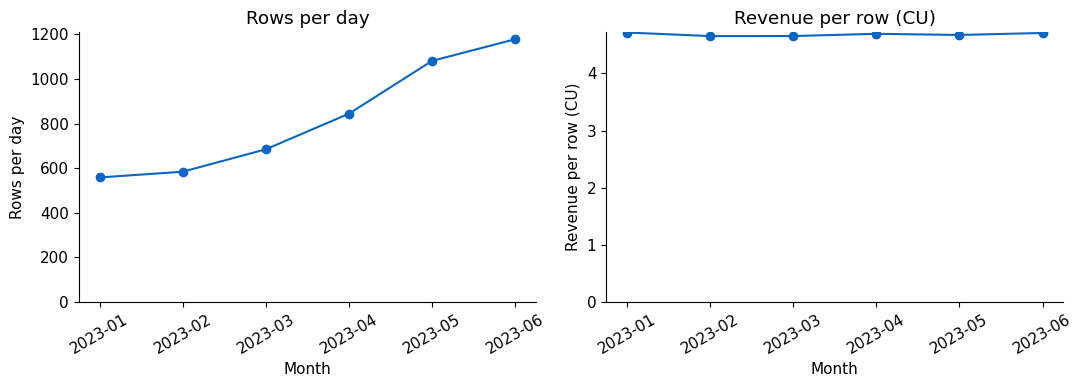

In [8]:
monthly_components = sales.groupby('month').agg(
    Records=('transaction_id', 'size'), Revenue=('revenue', 'sum'), Days=('date', 'nunique'))
monthly_components['Rows per day'] = monthly_components.Records / monthly_components.Days
monthly_components['Revenue per row (CU)'] = monthly_components.Revenue / monthly_components.Records
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column in zip(axes, ['Rows per day', 'Revenue per row (CU)']):
    monthly_components[column].plot(ax=ax, marker='o', color=COLORS[0])
    ax.set_title(column); ax.set_ylabel(column); ax.set_xlabel('Month')
    ax.set_ylim(bottom=0)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
note(f'Average revenue per row ranges from {monthly_components["Revenue per row (CU)"].min():.2f} to {monthly_components["Revenue per row (CU)"].max():.2f} CU. Revenue per row stays comparatively stable while sale rows per day increase. The revenue growth is therefore mainly associated with more recorded activity.')

## 9. Daily variation

Monthly averages hide quiet and busy days. These box plots show the spread of daily units at each shop: the box contains the middle half of days, and the line inside marks the median.

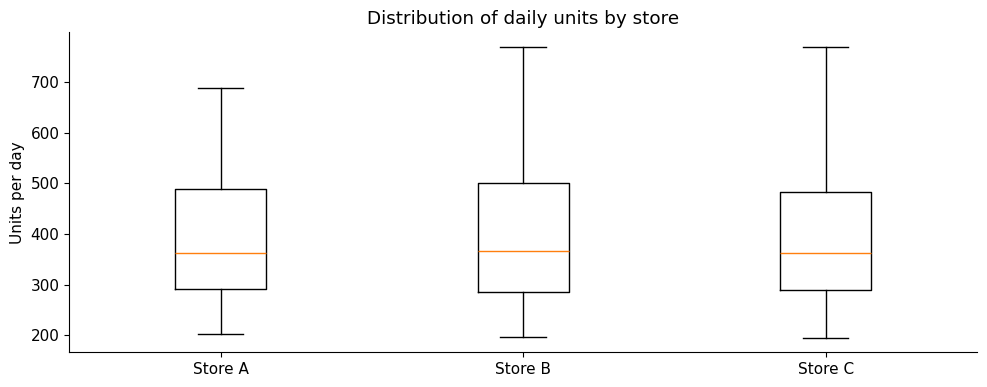

,min,median,max
store_id,,,
Store A,202,362.0,688
Store B,196,367.0,770
Store C,195,363.0,769


In [9]:
groups = [daily.loc[daily.store_id.eq(store), 'units'] for store in store_names.index]
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(groups, tick_labels=store_names.tolist())
ax.set_title('Distribution of daily units by store'); ax.set_ylabel('Units per day')
plt.tight_layout(); plt.show()
display(daily.groupby('store_id').units.agg(['min', 'median', 'max']).rename(index=store_names))
note('These plots combine all six months, so the spread also includes the growth seen in the monthly chart. Values outside the whiskers are retained as observed sales.')

## 10. Weekly patterns

Do the shops sell more on particular weekdays? We compare average daily units, rather than totals, because some weekdays occur more often in the calendar than others.

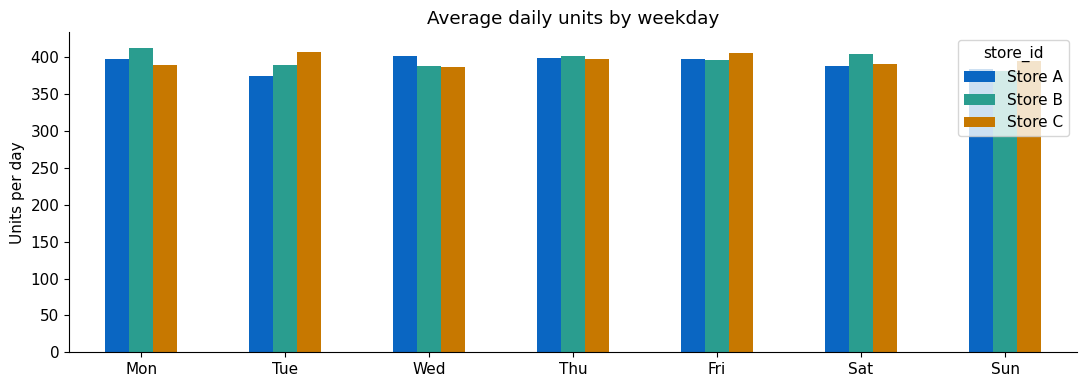

In [10]:
daily['weekday'] = daily.date.dt.dayofweek
weekday_sales = daily.groupby(['weekday', 'store_id']).units.mean().unstack()
weekday_sales.columns = weekday_sales.columns.map(store_names)
weekday_sales.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday_sales.plot.bar(color=COLORS, rot=0, figsize=(11, 4))
plt.title('Average daily units by weekday'); plt.ylabel('Units per day'); plt.xlabel('')
plt.tight_layout(); plt.show()
network_weekday = network_daily.groupby(network_daily.index.dayofweek).units.mean()
note(f'Network weekday averages range from {network_weekday.min():,.0f} to {network_weekday.max():,.0f} units per day. The combined averages show only a small difference across weekdays.')

## 11. Hourly patterns

We next look within the day to find the busiest hours. Each heatmap cell shows a shop’s average units sold at that hour per calendar day; darker cells mean more sales.

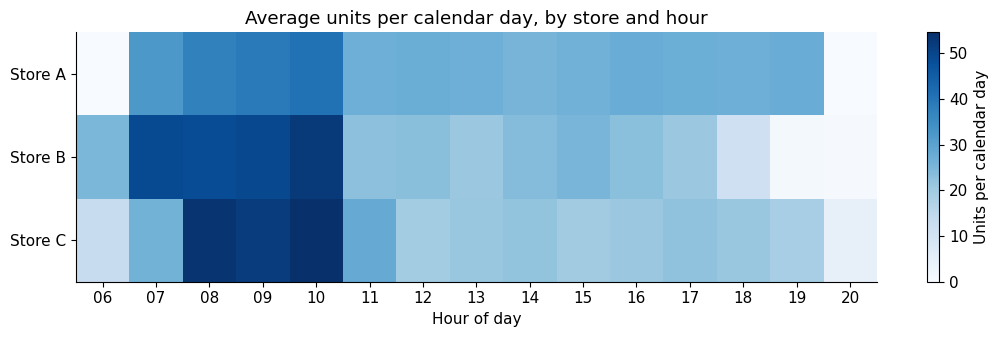

In [11]:
hours = range(int(sales.hour.min()), int(sales.hour.max()) + 1)
hourly = sales.groupby(['store_label', 'hour']).transaction_qty.sum().unstack(fill_value=0)
hourly = hourly.reindex(columns=hours, fill_value=0) / len(calendar)
fig, ax = plt.subplots(figsize=(11, 3.5))
image = ax.imshow(hourly, aspect='auto', cmap='Blues')
ax.set_xticks(range(len(hours)), [f'{hour:02d}' for hour in hours])
ax.set_yticks(range(len(hourly)), hourly.index)
ax.set_xlabel('Hour of day'); ax.set_title('Average units per calendar day, by store and hour')
fig.colorbar(image, ax=ax, label='Units per calendar day')
plt.tight_layout(); plt.show()
peak_hour = int(sales.groupby('hour').transaction_qty.sum().idxmax())
note(f'The highest aggregate recorded volume occurs during {peak_hour:02d}:00–{peak_hour:02d}:59. These are recorded sales patterns; the file does not specify opening hours.')

## 12. Sales by category

To understand what the shops need to prepare, we move from total sales to the product mix. We compare each category’s share of units and revenue, then check whether the mix differs across shops.

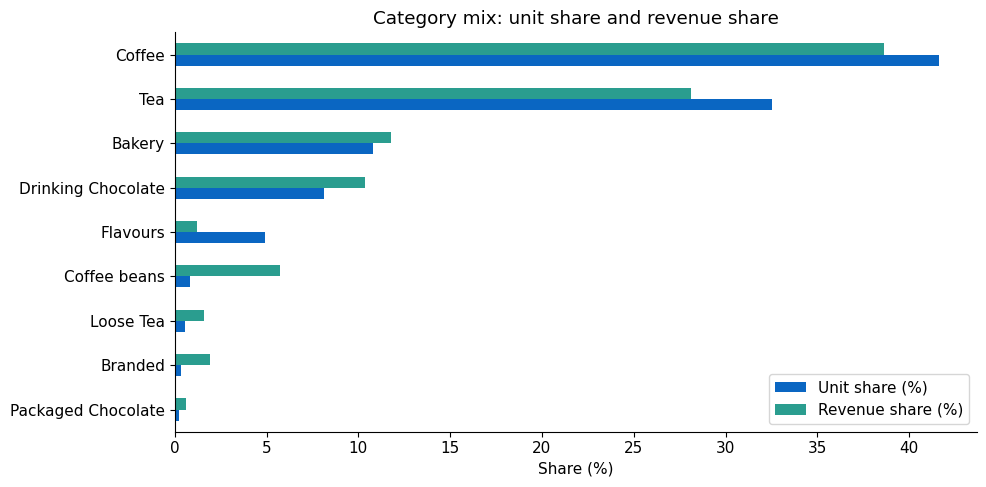

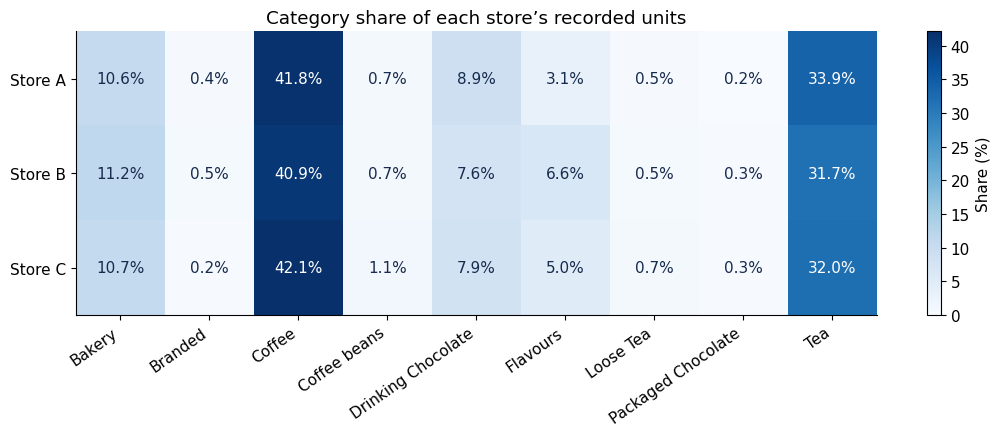

In [12]:
category = sales.groupby('product_category').agg(
    Units=('transaction_qty', 'sum'), Revenue=('revenue', 'sum'))
category['Unit share (%)'] = category.Units / category.Units.sum() * 100
category['Revenue share (%)'] = category.Revenue / category.Revenue.sum() * 100
category = category.sort_values('Units')
category[['Unit share (%)', 'Revenue share (%)']].plot.barh(color=COLORS[:2], figsize=(10, 5))
plt.title('Category mix: unit share and revenue share'); plt.xlabel('Share (%)'); plt.ylabel('')
plt.tight_layout(); plt.show()
store_mix = pd.crosstab(sales.store_label, sales.product_category,
                       values=sales.transaction_qty, aggfunc='sum').fillna(0)
store_mix = store_mix.div(store_mix.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(11, 4.5))
image = ax.imshow(store_mix, aspect='auto', cmap='Blues', vmin=0, vmax=store_mix.to_numpy().max())
ax.set_xticks(range(len(store_mix.columns)), store_mix.columns, rotation=35, ha='right')
ax.set_yticks(range(len(store_mix)), store_mix.index)
for row in range(len(store_mix)):
    for column in range(len(store_mix.columns)):
        value = store_mix.iloc[row, column]
        ax.text(column, row, f'{value:.1f}%', ha='center', va='center',
                color='white' if value > store_mix.to_numpy().max() / 2 else '#172b4d')
ax.set_title('Category share of each store’s recorded units')
fig.colorbar(image, ax=ax, label='Share (%)')
plt.tight_layout(); plt.show()
note(f'Coffee accounts for about {store_mix["Coffee"].min():.0f}–{store_mix["Coffee"].max():.0f}% of units sold at each shop, followed by Tea at about {store_mix["Tea"].min():.0f}–{store_mix["Tea"].max():.0f}%. The three shops have a similar category mix.')

## 13. Sales by product

Category totals can hide large differences between products. The ten highest-volume products show whether sales are concentrated in a few items or spread across the wider menu.

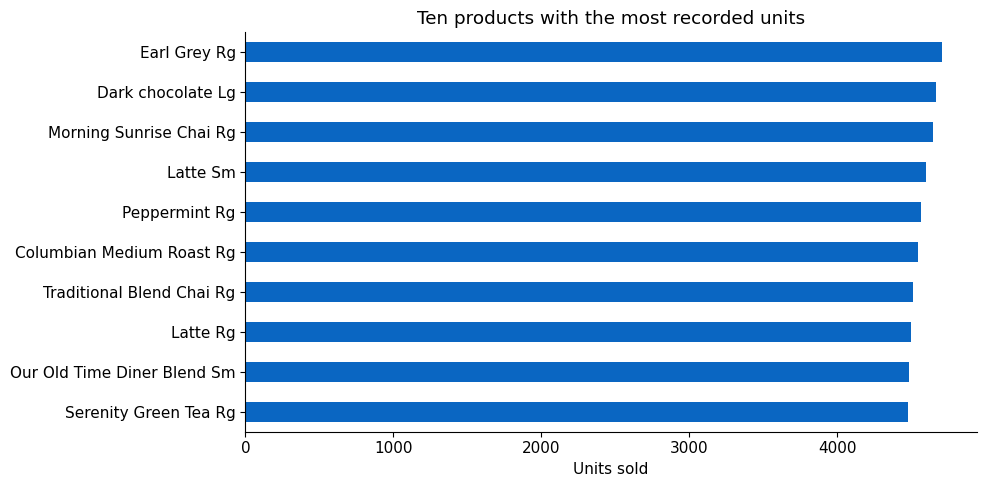

In [13]:
mapping = pd.read_csv(ROOT / 'data/assumptions/product_mapping.csv')
product_names = mapping.set_index('product_id').product_detail
product_units = sales.groupby('product_id').transaction_qty.sum()
top_products = product_units.nlargest(10).sort_values()
top_products.index = top_products.index.map(product_names)
top_products.plot.barh(color=COLORS[0], figsize=(10, 5))
plt.title('Ten products with the most recorded units'); plt.xlabel('Units sold'); plt.ylabel('')
plt.tight_layout(); plt.show()
note(f'The ten largest products account for {100 * product_units.nlargest(10).sum() / product_units.sum():.1f}% of units. Most units therefore come from the remaining products. All {len(product_units)} products stay in the analysis.')

## 14. Sales to stock requirements

The hub stocks ingredients and packaging for prepared drinks, and finished products for direct resale. The BOM translates daily product quantities into these stock requirements. The example below shows the ingredients and packaging associated with Latte sales.

In [14]:
product_index = pd.MultiIndex.from_product(
    [store_names.index, calendar, mapping.product_id], names=['store_id', 'date', 'product_id'])
product_daily = sales.groupby(['store_id', 'date', 'product_id']).transaction_qty.sum()
product_daily = product_daily.reindex(product_index, fill_value=0).rename('units').reset_index()
bom = pd.read_csv(ROOT / 'data/assumptions/bom.csv')
materials = pd.read_csv(ROOT / 'data/assumptions/materials.csv')
assert not bom.duplicated(['product_id', 'material_id']).any()
assert set(mapping.product_id) == set(bom.product_id)
assert materials.material_id.is_unique
assert bom.quantity_per_sale.gt(0).all()
expanded = product_daily.merge(bom, on='product_id', validate='many_to_many')
expanded['requirement'] = expanded.units * expanded.quantity_per_sale
requirements = expanded.groupby(['store_id', 'date', 'material_id']).requirement.sum().reset_index()
requirements = requirements.merge(materials, on='material_id', validate='many_to_one')
display(materials.groupby(['inventory_type', 'unit']).size().rename('Stock items').to_frame())
example = expanded.loc[(expanded.product_id == 38) & (expanded.units > 0)]
example = example.loc[example.date.eq(example.date.min())].head(4)
example = example.merge(materials[['material_id', 'material_name']], on='material_id', validate='many_to_one')
first = example.iloc[0]
note(f'Example: {int(first.units)} {product_names.loc[38]} units sold at {store_names.loc[first.store_id]} on {first.date:%d %b %Y}.')
readable_example = example[['material_name', 'quantity_per_sale', 'units', 'requirement', 'unit']].copy()
readable_example.columns = ['Stock item', 'Per Latte', 'Lattes sold', 'Required quantity', 'Unit']
display(readable_example.set_index('Stock item'))
note('Stock requirement = units sold × quantity per sale in the BOM. These are requirements calculated from the defined recipes, not measured ingredient consumption.')

Stock items
inventory_type unit             
Finished goods each           39
Ingredient     L               1
               kg             17
Packaging      each            7

,Per Latte,Lattes sold,Required quantity,Unit
Stock item,,,,
House espresso beans,0.018,10,0.18,kg
Dairy milk,0.180,10,1.80,L
Small cup,1.000,10,10.00,each
Small lid,1.000,10,10.00,each


## 15. Forecasting handoff

Finally, we add the three shops’ requirements together for the central hub. The examples show daily milk, small-cup and Chocolate Croissant requirements. Each chart keeps its own unit and scale.

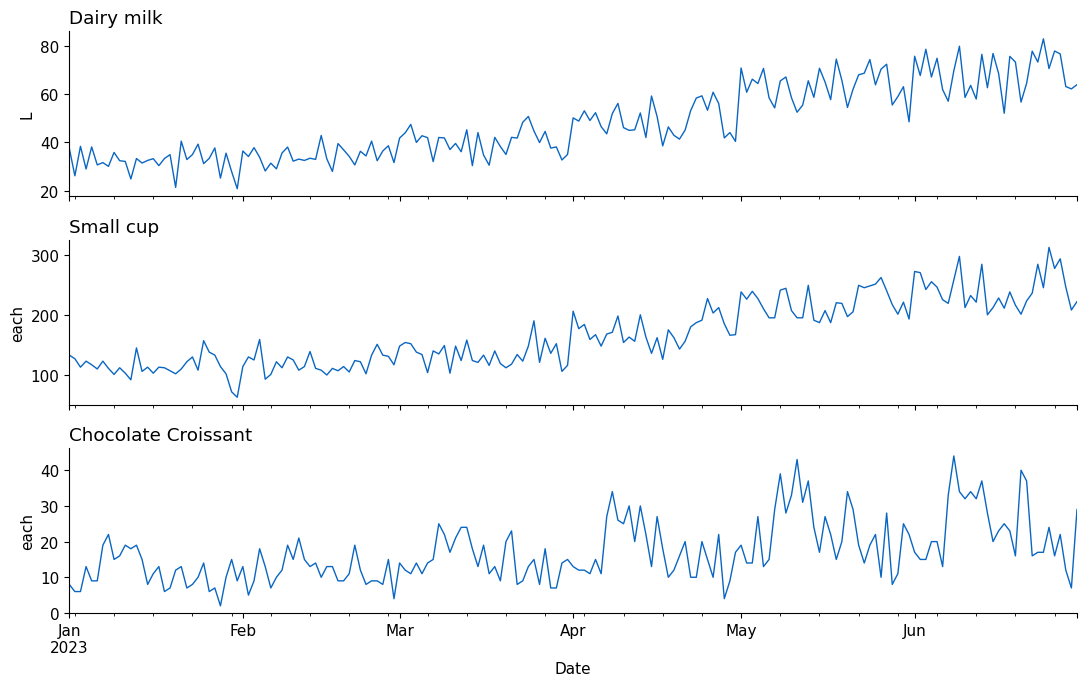

In [15]:
network_requirements = requirements.groupby(['date', 'material_id']).requirement.sum().unstack(fill_value=0)
examples = ['milk', 'cup_sm', 'finished_71']
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, material_id in zip(axes, examples):
    item = materials.set_index('material_id').loc[material_id]
    network_requirements[material_id].plot(ax=ax, color=COLORS[0], linewidth=1)
    ax.set_title(item.material_name, loc='left')
    ax.set_ylabel(item.unit)
axes[-1].set_xlabel('Date')
plt.tight_layout(); plt.show()
assert np.isclose(product_daily.units.sum(), sales.transaction_qty.sum())
assert len(requirements) == len(store_names) * len(calendar) * len(materials)
out = ROOT / 'results/eda'
out.mkdir(parents=True, exist_ok=True)
daily.to_csv(out / 'daily_sales.csv', index=False)
requirements.to_csv(out / 'daily_requirements.csv', index=False)
note(f'The result is {network_requirements.shape[1]} daily stock-item histories for the hub, each covering {len(network_requirements)} days.')
note('Sales activity has grown, the shops contribute similar revenue shares, and most units lie outside the ten busiest products. Demand Forecasting uses the full set of stock histories to compare weekly and monthly forecasts.')